In [1]:
import sys
import os

import h5py

from matplotlib import pyplot as plt

import numpy as np
import scipy as sp
import pandas as pd

from sklearn.decomposition import PCA


sys.path.append(os.path.join(os.getcwd(), '../../'))

# noinspection PyUnresolvedReferences
from utils import read_utils
# noinspection PyUnresolvedReferences
from utils import plot_utils
# noinspection PyUnresolvedReferences
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/fly-2023-schaffer/data_exploration/manifold/../../utils/train_utils.py'>

In [3]:
read_ids = list(range(0, 12+1))
# read_ids = [0, 2, 3, 8, 9]
plot_id = 0

dims = 3

# selection_n = ['DD01', 'VB02', 'SMDDR', 'AVAR']
# selection_bhl = ['undefined', 'quiescence', 'ab_bending', 'grooming_b', 'grooming_f', 'running']

In [4]:
path = os.path.join(read_utils.get_data_path(), 'fly-2023-schaffer/brain')

(file_ids, filenames,
 traces,
 states, markers) = read_utils.get_data(path, read_ids)

# # clear nan values
# for i in range(len(file_ids)):
# 	mask = markers[i].notna().all(axis=1)
#
# 	traces[i] = traces[i][mask]
# 	markers[i] = markers[i][mask]
# 	states[i] = states[i][mask]
#
# 	#filenames[i] = filenames[i][mask]

# # remove unused discrete state labels
# states = [ds[selection_bhl] for ds in states]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

In [5]:
(modes_manifold,
 recos_manifold,
 loads_pca_man,
 vars_expl_mans) = train_utils.get_manifolds_pca(traces,
												 n_pc=dims)

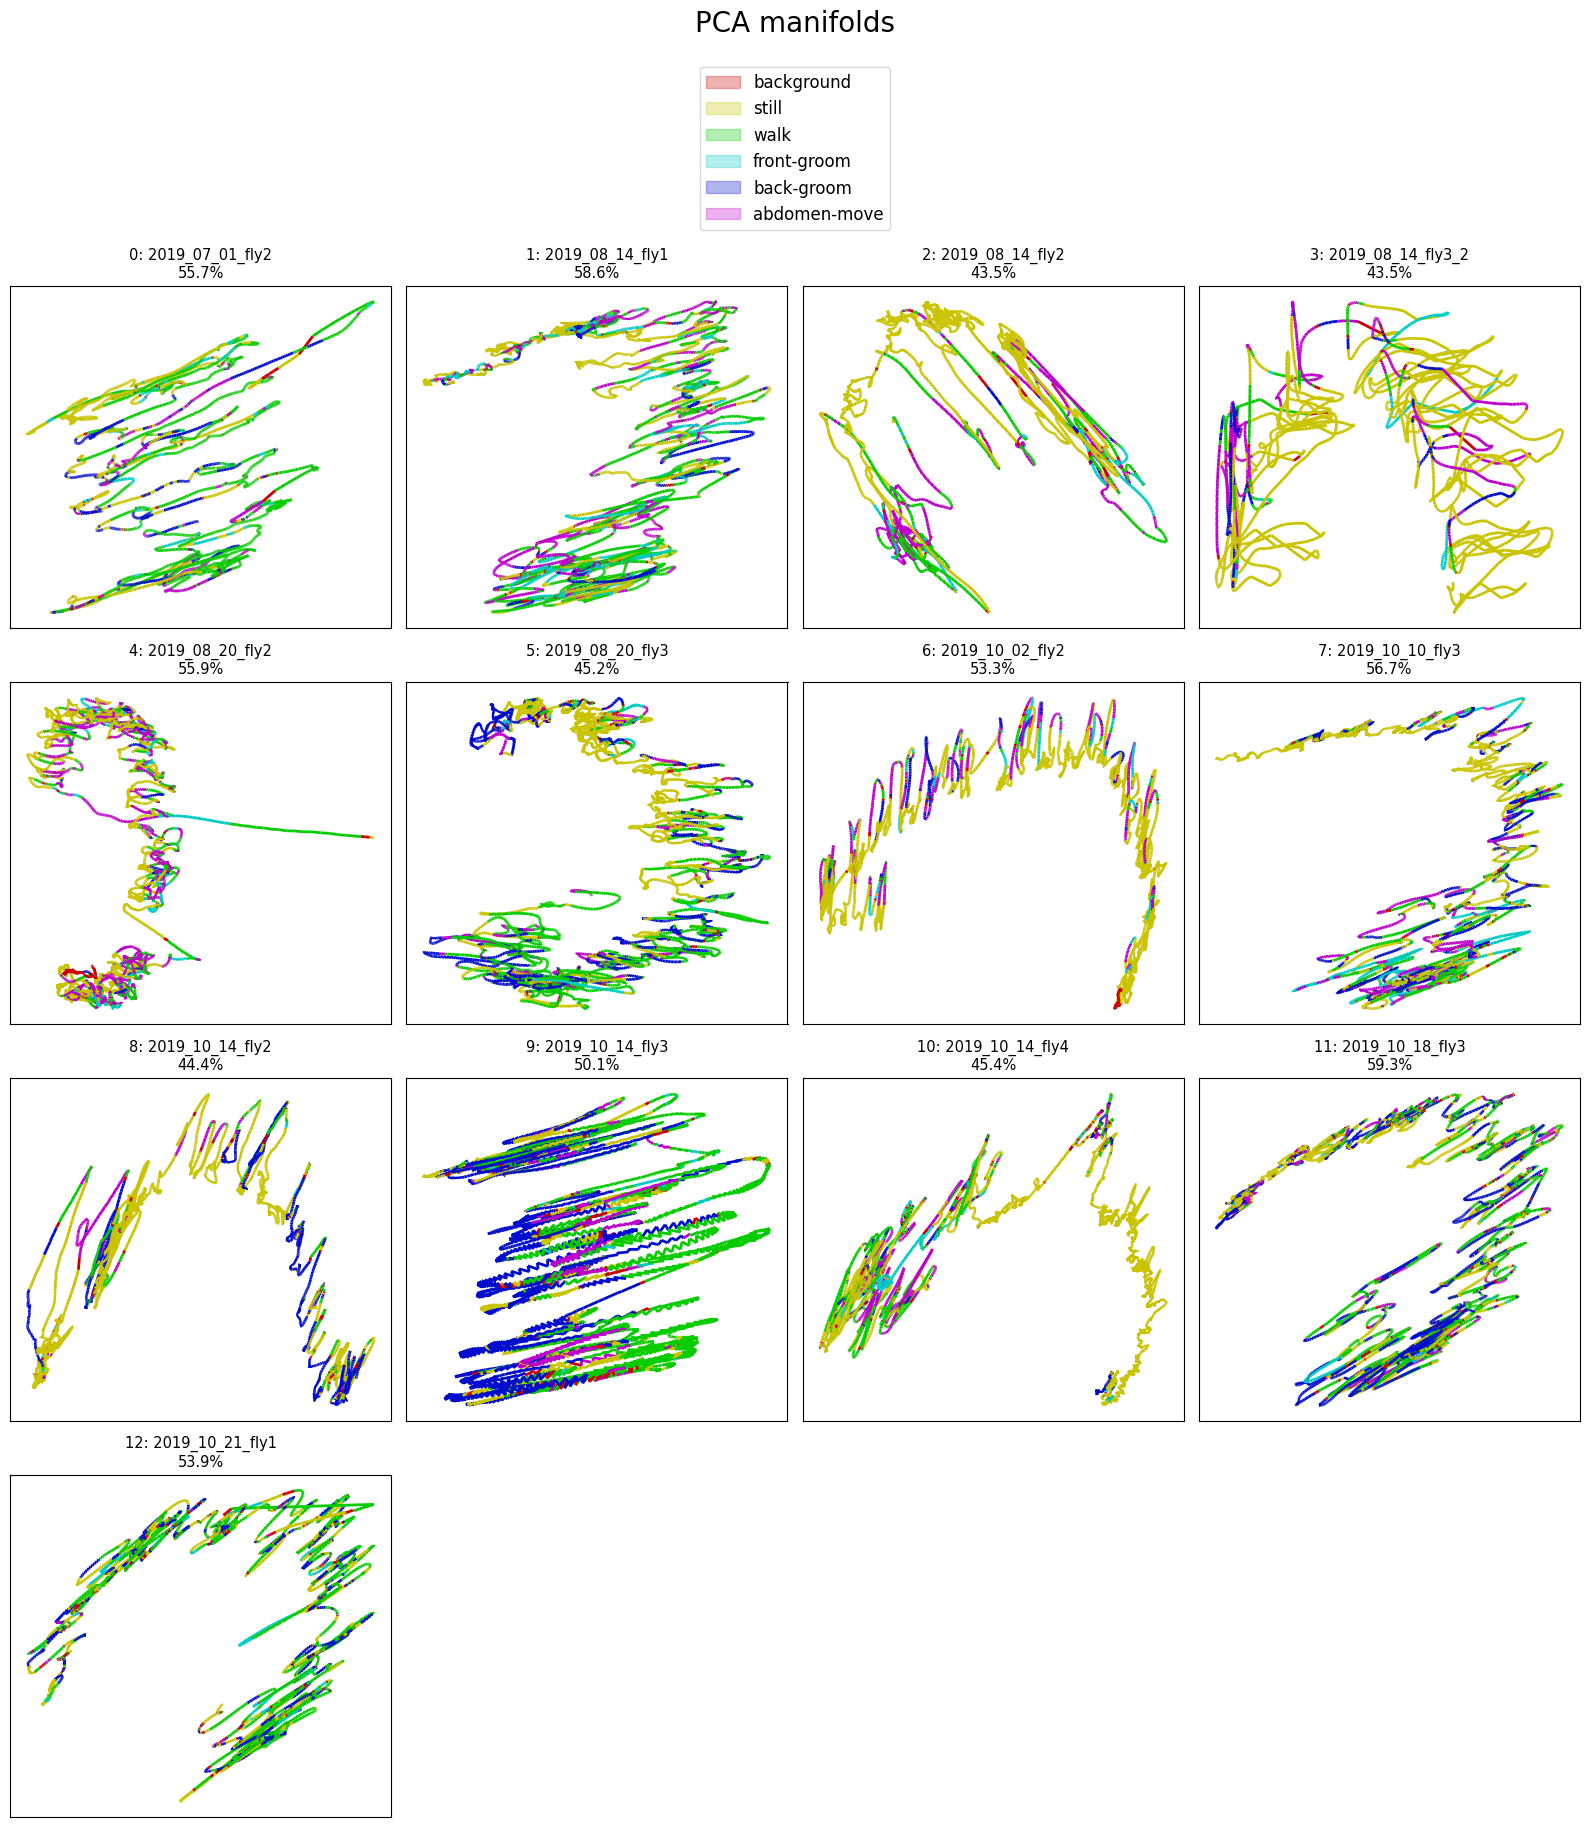

51.2%


In [6]:
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
						  modes_manifold, states,
						  [vx[:2] for vx in vars_expl_mans], None,
						  title='PCA manifolds', top_space=2.5, save_name=None)

In [7]:
# plot_utils.plot_manifolds_3d([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
# 						  modes_manifold, states,
# 						  [vx[:3] for vx in vars_expl_mans], None,
# 						  title='PCA manifolds', top_space=3.5)

In [8]:
traces_manifolds_indices = [np.argsort(xloads_pca_man[0, :]) for xloads_pca_man in loads_pca_man]

traces_sorted = [t.iloc[:, t_man_idx.tolist()] for t, t_man_idx in zip(traces, traces_manifolds_indices)]
traces_manifolds_sorted = [t_man.iloc[:, t_man_idx.tolist()] for t_man, t_man_idx in zip(recos_manifold, traces_manifolds_indices)]

# fly 0

In [9]:
plt.figure(figsize=(12, 6))
plt.imshow(np.clip(traces_sorted[file_ids.index(0)].T, -0.015, 0.015), aspect='auto', cmap='plasma')

In [ ]:
plt.figure(figsize=(12, 6))
plt.imshow(np.clip(traces_manifolds_sorted[file_ids.index(0)].T, -0.015, 0.015), aspect='auto', cmap='plasma')

# fly 2

In [ ]:
# plot
plt.figure(figsize=(12, 6))
plt.imshow(np.clip(traces_sorted[file_ids.index(2)].T, -0.015, 0.015), aspect='auto', cmap='plasma')

In [ ]:
plt.figure(figsize=(12, 6))
plt.imshow(np.clip(traces_manifolds_sorted[file_ids.index(2)].T, -0.015, 0.015), aspect='auto', cmap='plasma')

# fly 3

In [ ]:
# plot
plt.figure(figsize=(12, 6))
plt.imshow(np.clip(traces_sorted[file_ids.index(3)].T, -0.015, 0.015), aspect='auto', cmap='plasma')

In [ ]:
plt.figure(figsize=(12, 6))
plt.imshow(np.clip(traces_manifolds_sorted[file_ids.index(3)].T, -0.015, 0.015), aspect='auto', cmap='plasma')

# fly 8


In [ ]:
# plot
plt.figure(figsize=(12, 6))
plt.imshow(np.clip(traces_sorted[file_ids.index(8)].T, -0.015, 0.015), aspect='auto', cmap='plasma')

In [ ]:
plt.figure(figsize=(12, 6))
plt.imshow(np.clip(traces_manifolds_sorted[file_ids.index(8)].T, -0.015, 0.015), aspect='auto', cmap='plasma')

# fly 9

In [ ]:
# plot
plt.figure(figsize=(12, 6))
plt.imshow(np.clip(traces_sorted[file_ids.index(9)].T, -0.015, 0.015), aspect='auto', cmap='plasma')

In [ ]:
plt.figure(figsize=(12, 6))
plt.imshow(np.clip(traces_manifolds_sorted[file_ids.index(9)].T, -0.015, 0.015), aspect='auto', cmap='plasma')